In [ ]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.io import imread
from skimage.transform import resize
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score,f1_score, classification_report)

In [ ]:
categories = ['Diseased', 'Healthy']

train_dir = '..\\Augmentation\\Augmented DataSet\\Train'
test_dir  = '..\\Augmentation\\Augmented DataSet\\Test'


def load_split(base_dir, categories):
    features = []
    labels = []

    for label_idx, cat in enumerate(categories):
        folder = os.path.join(base_dir, cat)
        print(f'Loading {cat} from {base_dir}')

        for fname in os.listdir(folder):
            img = imread(os.path.join(folder, fname))

            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            gray = cv2.GaussianBlur(gray, (7, 7), 0)

            # Adaptive Gaussian Thresholding
            seg = cv2.adaptiveThreshold(gray, 255,
                                         cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                         cv2.THRESH_BINARY, 11, 2)

            seg = resize(seg, (64, 64))
            features.append(seg.flatten())
            labels.append(label_idx)

        print(f'Done: {cat}')

    return np.array(features), np.array(labels)


X_train, y_train = load_split(train_dir, categories)
X_test, y_test = load_split(test_dir, categories)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Loading Diseased from ..\Augmentation\Augmented DataSet\Train
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Train
Done: Healthy
Loading Diseased from ..\Augmentation\Augmented DataSet\Test
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Test
Done: Healthy
Training Shape : (5600, 4096)
Testing Shape  : (1400, 4096)


In [26]:
print("Training samples :", len(X_train))
print("Testing samples  :", len(X_test))

Training samples : 5600
Testing samples  : 1400


In [27]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [28]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    y_pred = model.predict(X_te)
    acc    = accuracy_score(y_te, y_pred)
    prec   = precision_score(y_te, y_pred, average='weighted')
    rec    = recall_score(y_te, y_pred, average='weighted')
    f1     = f1_score(y_te, y_pred)
    tr_acc = accuracy_score(y_tr, model.predict(X_tr))

    print(f'{name}')
    print(classification_report(y_te, y_pred))
    print(f'Accuracy:          {round(acc*100, 2)} %')
    print(f'Precision:         {round(prec*100, 2)} %')
    print(f'Recall:            {round(rec*100, 2)} %')
    print(f'F1 Score:          {round(f1*100, 2)} %')
    print(f'Training Accuracy: {round(tr_acc*100, 2)} %')

    cf = confusion_matrix(y_te, y_pred)
    sns.heatmap(cf / cf.sum(), annot=True, fmt='.2%', cmap = "Blues")
    plt.title(name)
    plt.show()
    return acc, prec, rec, f1

### Decision Tree

Decision Tree
              precision    recall  f1-score   support

           0       0.63      0.63      0.63       700
           1       0.63      0.64      0.63       700

    accuracy                           0.63      1400
   macro avg       0.63      0.63      0.63      1400
weighted avg       0.63      0.63      0.63      1400

Accuracy:          63.21 %
Precision:         63.21 %
Recall:            63.21 %
F1 Score:          63.35 %
Training Accuracy: 99.71 %


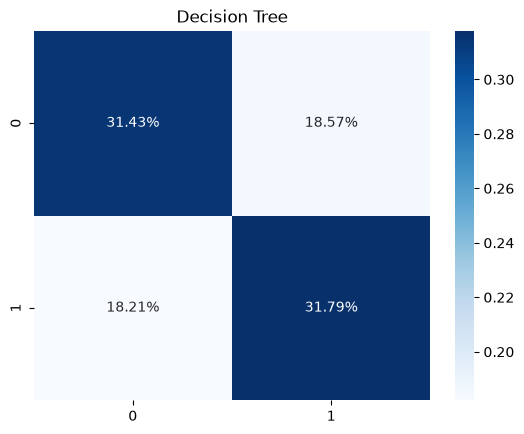

In [29]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=25, random_state=42)
dt.fit(X_train, y_train)
acc_dt, prec_dt, rec_dt, f1_dt = evaluate(
    'Decision Tree', dt, X_train, y_train, X_test, y_test)

### Naive Bayes

Naive Bayes
              precision    recall  f1-score   support

           0       0.87      0.78      0.82       700
           1       0.80      0.89      0.84       700

    accuracy                           0.83      1400
   macro avg       0.84      0.83      0.83      1400
weighted avg       0.84      0.83      0.83      1400

Accuracy:          83.21 %
Precision:         83.64 %
Recall:            83.21 %
F1 Score:          84.11 %
Training Accuracy: 87.54 %


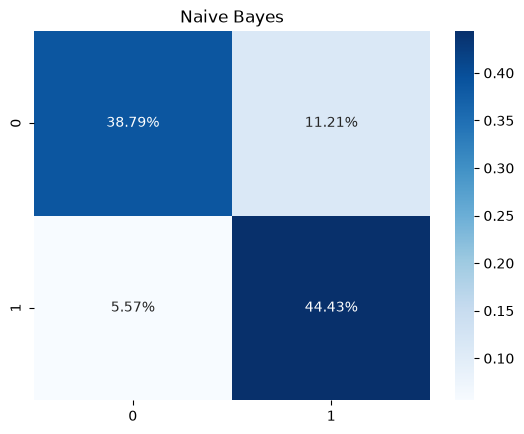

In [30]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
acc_nb, prec_nb, rec_nb, f1_nb = evaluate(
    'Naive Bayes', nb, X_train, y_train, X_test, y_test)

### Logistic Regression

Logistic Regression
              precision    recall  f1-score   support

           0       0.70      0.67      0.69       700
           1       0.68      0.72      0.70       700

    accuracy                           0.69      1400
   macro avg       0.69      0.69      0.69      1400
weighted avg       0.69      0.69      0.69      1400

Accuracy:          69.36 %
Precision:         69.41 %
Recall:            69.36 %
F1 Score:          70.1 %
Training Accuracy: 100.0 %


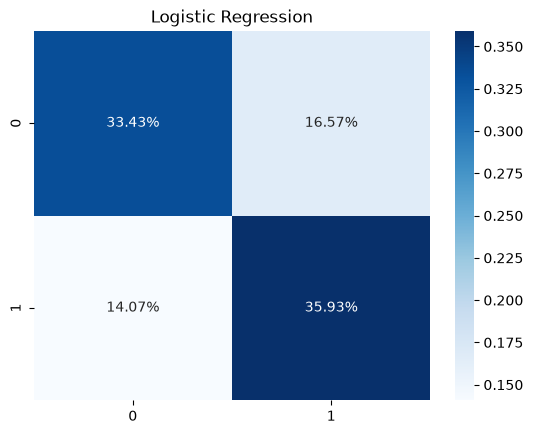

In [31]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(solver='liblinear', random_state=42)
lr.fit(X_train, y_train)
acc_lr, prec_lr, rec_lr, f1_lr = evaluate(
    'Logistic Regression', lr, X_train, y_train, X_test, y_test)

### KNN

K-Nearest Neighbors
              precision    recall  f1-score   support

           0       0.70      0.09      0.15       700
           1       0.51      0.96      0.67       700

    accuracy                           0.52      1400
   macro avg       0.61      0.52      0.41      1400
weighted avg       0.61      0.52      0.41      1400

Accuracy:          52.43 %
Precision:         60.53 %
Recall:            52.43 %
F1 Score:          66.93 %
Training Accuracy: 65.05 %


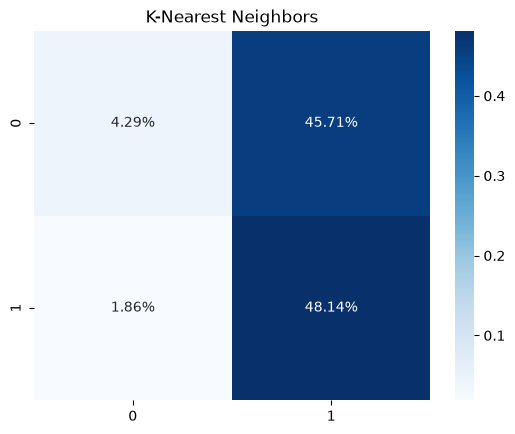

In [32]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
acc_knn, prec_knn, rec_knn, f1_knn = evaluate(
    'K-Nearest Neighbors', knn, X_train, y_train, X_test, y_test)

### Random Forest

Random Forest
              precision    recall  f1-score   support

           0       0.87      0.80      0.83       700
           1       0.81      0.88      0.84       700

    accuracy                           0.84      1400
   macro avg       0.84      0.84      0.84      1400
weighted avg       0.84      0.84      0.84      1400

Accuracy:          83.86 %
Precision:         84.06 %
Recall:            83.86 %
F1 Score:          84.46 %
Training Accuracy: 100.0 %


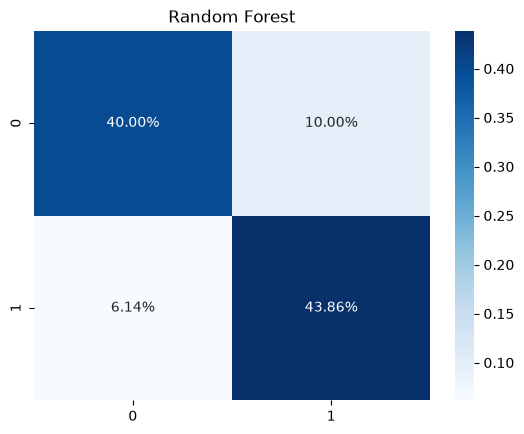

In [33]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
acc_rf, prec_rf, rec_rf, f1_rf = evaluate(
    'Random Forest', rf, X_train, y_train, X_test, y_test)

### Voting

Soft Voting
              precision    recall  f1-score   support

           0       0.88      0.69      0.77       700
           1       0.75      0.91      0.82       700

    accuracy                           0.80      1400
   macro avg       0.81      0.80      0.80      1400
weighted avg       0.81      0.80      0.80      1400

Accuracy:          79.79 %
Precision:         81.24 %
Recall:            79.79 %
F1 Score:          81.75 %
Training Accuracy: 99.77 %


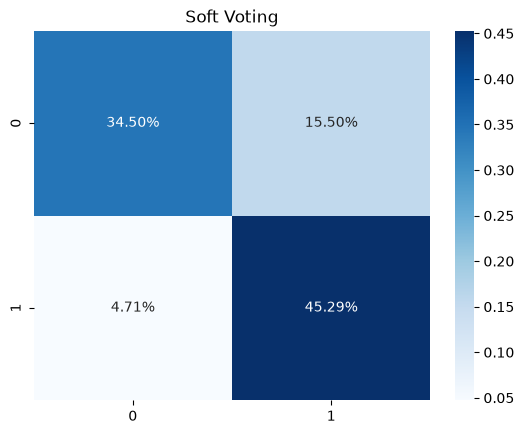

Hard Voting
              precision    recall  f1-score   support

           0       0.88      0.72      0.79       700
           1       0.76      0.90      0.82       700

    accuracy                           0.81      1400
   macro avg       0.82      0.81      0.81      1400
weighted avg       0.82      0.81      0.81      1400

Accuracy:          80.93 %
Precision:         81.95 %
Recall:            80.93 %
F1 Score:          82.49 %
Training Accuracy: 99.84 %


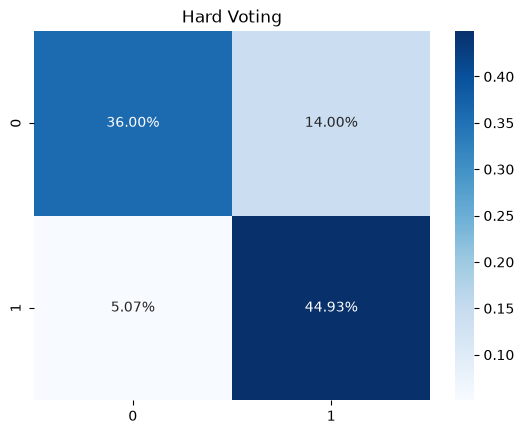

In [34]:
from sklearn.ensemble import VotingClassifier

base_estimators = [('dt', dt), ('nb', nb), ('lr', lr), ('knn', knn), ('rf', rf)]

# Soft Voting
soft_vc = VotingClassifier(estimators=base_estimators, voting='soft')
soft_vc.fit(X_train, y_train)
acc_sv, prec_sv, rec_sv, f1_sv = evaluate(
    'Soft Voting', soft_vc, X_train, y_train, X_test, y_test)

# Hard Voting
hard_vc = VotingClassifier(estimators=base_estimators, voting='hard')
hard_vc.fit(X_train, y_train)
acc_hv, prec_hv, rec_hv, f1_hv = evaluate(
    'Hard Voting', hard_vc, X_train, y_train, X_test, y_test)

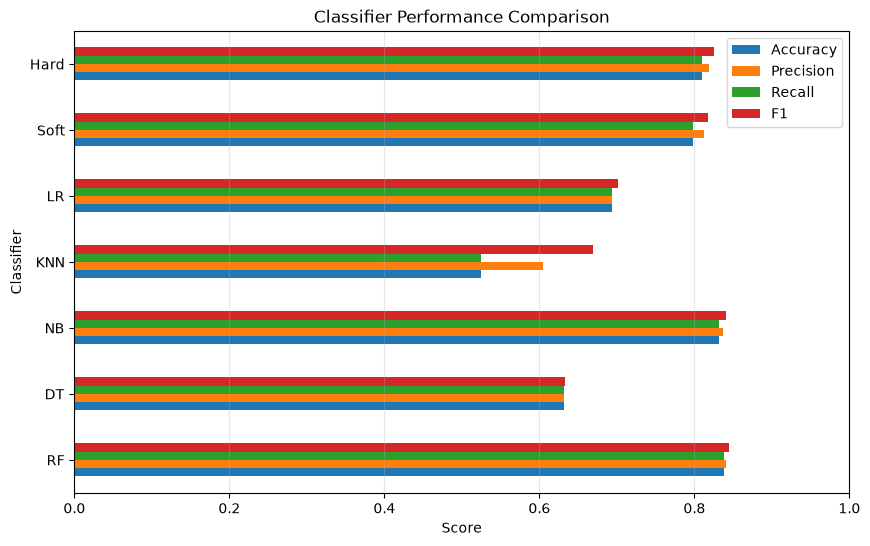

In [35]:
clf_names = ['RF', 'DT', 'NB', 'KNN', 'LR', 'Soft', 'Hard']
Accuracy  = [acc_rf,   acc_dt,   acc_nb,   acc_knn,   acc_lr,   acc_sv,   acc_hv]
Precision = [prec_rf,  prec_dt,  prec_nb,  prec_knn,  prec_lr,  prec_sv,  prec_hv]
Recall    = [rec_rf,   rec_dt,   rec_nb,   rec_knn,   rec_lr,   rec_sv,   rec_hv]
F1        = [f1_rf,    f1_dt,    f1_nb,    f1_knn,    f1_lr,    f1_sv,    f1_hv]


df = pd.DataFrame({
    'Accuracy': Accuracy,
    'Precision': Precision,
    'Recall': Recall,
    'F1': F1
}, index=clf_names)

df.plot(kind='barh', figsize=(10,6))

plt.xlabel("Score")
plt.ylabel("Classifier")
plt.xlim(0,1)
plt.grid(axis='x', alpha=0.3)
plt.title("Classifier Performance Comparison")
plt.show()